# Chapter 03: Where Fleet Priors Come From — Python Laboratory
### *The Principle of Maximum Entropy (MaxEnt), The Brandeis Dice Problem & Empirical Bayes*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/03_maximum_entropy_priors.ipynb) | [Prev: Ch 02: Relative Entropy (Python)](02_relative_entropy_and_prior_penalties.ipynb) | [Next: Ch 04: Mutual Information (Python)](04_mutual_information_and_venn_geometry.ipynb)**

---

## 1. The Core Critique: "Where Did You Get That Prior?"

Critics of Bayesian inference often ask: *"Aren't priors arbitrary?"* E.T. Jaynes answered this with the **Principle of Maximum Entropy (MaxEnt)**:

> **Choose the prior distribution that maximizes Shannon entropy $H(p)$ subject to your known physical constraints (and nothing else).**

Any distribution with *lower* entropy than the MaxEnt distribution is smuggling in hidden assumptions you did not state! Let's import our libraries and solve Jaynes's classic MaxEnt problems numerically.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Environment initialized successfully.")


Environment initialized successfully.


---

## 2. The Physical Metaphor: The Brandeis Dice Problem

Suppose a 6-sided die is rolled many times and we only know its **average face value** is $\mu \neq 3.5$ (say $\mu = 4.5$). Among all probability vectors $p = (p_1, \dots, p_6)$ with $\sum i\, p_i = \mu$, which one assumes the least beyond that constraint?

Maximizing $H(p) = -\sum p_i \ln p_i$ via Lagrange multipliers yields the **exponential family (Boltzmann) distribution**:
$$p_i \propto e^{-\lambda i}$$
where $\lambda$ is tuned so the mean equals $\mu$. Notice that when $\mu = 3.5$, $\lambda = 0$ and MaxEnt recovers the **uniform die** $p_i = 1/6$!

In [2]:
def solve_brandeis_dice(target_mean):
    faces = np.arange(1, 7)
    
    # Negative entropy objective to minimize
    def objective(p):
        eps = 1e-15
        p_safe = np.clip(p, eps, 1.0)
        return float(np.sum(p_safe * np.log(p_safe)))
    
    constraints = [
        {'type': 'eq', 'fun': lambda p: np.sum(p) - 1.0},
        {'type': 'eq', 'fun': lambda p: np.sum(faces * p) - target_mean}
    ]
    
    # bounds: probabilities must be strictly positive and <= 1.0 for each face
    bounds = [(1e-6, 1.0) for _ in range(6)]
    # init_guess: uniform probability distribution 1/6 for each of 6 die faces
    init_guess = np.ones(6) / 6.0
    
    res = minimize(objective, init_guess, method='SLSQP', bounds=bounds, constraints=constraints)
    if not res.success:
        raise ValueError(f"Optimization failed: {res.message}")
    # res.x is the optimal probability vector [p1, p2, p3, p4, p5, p6]
    return res.x

means_to_test = [3.5, 4.0, 4.5, 5.0]
faces = np.arange(1, 7)

print("=" * 65)
print("             THE BRANDEIS DICE MAXENT DISTRIBUTIONS")
print("=" * 65)
for m in means_to_test:
    p_opt = solve_brandeis_dice(m)
    h_bits = -np.sum(p_opt * np.log2(p_opt))
    p_str = ", ".join([f"p{i}={p:.3f}" for i, p in zip(faces, p_opt)])
    print(f"Target Mean = {m:.1f} | Entropy = {h_bits:.4f} bits | {p_str}")
print("=" * 65)


             THE BRANDEIS DICE MAXENT DISTRIBUTIONS
Target Mean = 3.5 | Entropy = 2.5850 bits | p1=0.167, p2=0.167, p3=0.167, p4=0.167, p5=0.167, p6=0.167
Target Mean = 4.0 | Entropy = 2.5226 bits | p1=0.103, p2=0.123, p3=0.146, p4=0.174, p5=0.207, p6=0.247
Target Mean = 4.5 | Entropy = 2.3279 bits | p1=0.054, p2=0.079, p3=0.114, p4=0.165, p5=0.240, p6=0.347
Target Mean = 5.0 | Entropy = 1.9728 bits | p1=0.021, p2=0.039, p3=0.072, p4=0.136, p5=0.255, p6=0.478


---

## 3. Deriving Fleet Priors for Production Software Systems

Now apply the exact same MaxEnt principle to a continuous quantity with **non-negative support** ($x \ge 0$, such as time-to-failure or test latency) and a known **mean** $\mathbb{E}[X] = \mu$:
* The unique MaxEnt distribution on $[0, \infty)$ with fixed mean $\mu$ is the **Exponential distribution**:
  $$p(x) = \frac{1}{\mu} e^{-x/\mu}$$
* If the domain is bounded on $[0, 1]$ (e.g., a failure rate $\theta$) with no constraints, MaxEnt yields $\text{Uniform}(0, 1) = \text{Beta}(1, 1)$.

In [3]:
mu_fleet = 0.02
x_grid = np.linspace(0.0001, 0.15, 500)
dx = x_grid[1] - x_grid[0]

# Theoretical MaxEnt Exponential Density
p_exp = (1.0 / mu_fleet) * np.exp(-x_grid / mu_fleet)

# Verify empirical mean
emp_mean = np.sum(x_grid * p_exp * dx)
emp_area = np.sum(p_exp * dx)

print("=" * 60)
print(f"FLEET PRIOR VERIFICATION (Target Mean = {mu_fleet}):")
print(f"Integrated Area: {emp_area:.6f} (Should be 1.0)")
print(f"Calculated Mean: {emp_mean:.6f} (Should be {mu_fleet})")
print("=" * 60)


FLEET PRIOR VERIFICATION (Target Mean = 0.02):
Integrated Area: 1.001955 (Should be 1.0)
Calculated Mean: 0.019907 (Should be 0.02)


---

## 4. Visualizing the Brandeis Dice & Fleet Prior

Let's plot both discrete MaxEnt (the biased Brandeis die) and continuous MaxEnt (the Exponential fleet prior) to see how Lagrange multipliers smoothly tilt probability mass to satisfy the mean constraint without inventing spikes or sharp cutoffs.

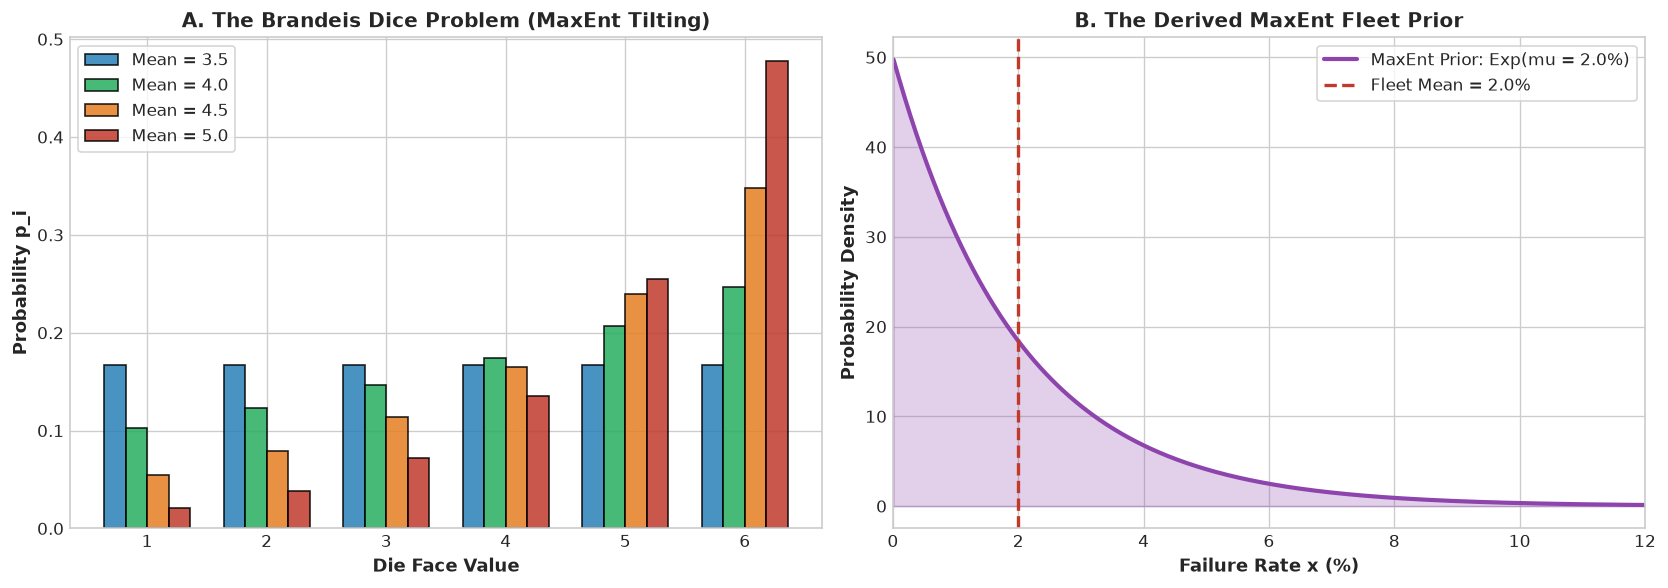

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Brandeis Dice Tilting
colors = ['#2980b9', '#27ae60', '#e67e22', '#c0392b']
x_faces = np.arange(1, 7)
width = 0.18

for idx, (m, c) in enumerate(zip(means_to_test, colors)):
    p_sol = solve_brandeis_dice(m)
    axes[0].bar(x_faces + (idx - 1.5) * width, p_sol, width=width, color=c, alpha=0.85,
                edgecolor='black', label=f'Mean = {m:.1f}')

axes[0].set_xlabel("Die Face Value", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Probability p_i", fontsize=11, fontweight='bold')
axes[0].set_title("A. The Brandeis Dice Problem (MaxEnt Tilting)", fontsize=12, fontweight='bold')
axes[0].set_xticks(x_faces)
axes[0].legend(frameon=True)

# Panel 2: The Continuous Fleet Prior
axes[1].plot(x_grid * 100, p_exp, color='#8e44ad', lw=2.5, 
            label=f'MaxEnt Prior: Exp(mu = {mu_fleet*100:.1f}%)')
axes[1].fill_between(x_grid * 100, p_exp, alpha=0.25, color='#8e44ad')
axes[1].axvline(mu_fleet * 100, color='#c0392b', ls='--', lw=2.0, label=f'Fleet Mean = {mu_fleet*100:.1f}%')
axes[1].set_xlabel("Failure Rate x (%)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Probability Density", fontsize=11, fontweight='bold')
axes[1].set_title("B. The Derived MaxEnt Fleet Prior", fontsize=12, fontweight='bold')
axes[1].set_xlim(0, 12)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()


---

## 5. The MaxEnt Taxonomy: Why the Gaussian Appears Everywhere

What if a variable lives on $(-\infty, \infty)$ and we know **both its mean $\mu$ and its variance $\sigma^2$**?
* Maximizing differential entropy $h(p) = -\int p(x) \ln p(x)\, dx$ subject to $\mathbb{E}[X]=\mu$ and $\text{Var}(X)=\sigma^2$ uniquely yields the **Normal (Gaussian) distribution** $\mathcal{N}(\mu, \sigma^2)$!

This is why Gaussians are the default prior for unbounded regression coefficients: they inject the **least possible extra structure** given a scale $\sigma$. Let's verify numerically that $\mathcal{N}(0, 1)$ beats Laplace and Uniform distributions of the *exact same variance* in differential entropy.

In [5]:
from scipy.stats import norm, laplace, uniform

# Variance sigma^2 = 1.0 for all distributions
# 1. Gaussian: N(0, 1) -> Var = 1
h_gauss = 0.5 * np.log2(2 * np.pi * np.e * 1.0)

# 2. Uniform on [-sqrt(3), sqrt(3)] -> Var = (2*sqrt(3))^2 / 12 = 1
h_unif = np.log2(2 * np.sqrt(3))

# 3. Laplace with b = 1/sqrt(2) -> Var = 2*b^2 = 1
b_laplace = 1.0 / np.sqrt(2.0)
h_laplace = np.log2(2.0 * b_laplace * np.e)

print("=" * 65)
print("DIFFERENTIAL ENTROPY COMPARISON (Fixed Variance sigma^2 = 1.0):")
print(f"1. Gaussian N(0, 1):      {h_gauss:.4f} bits (THE THEORETICAL MAXIMUM)")
print(f"2. Laplace (Var = 1):     {h_laplace:.4f} bits (Gap: {h_gauss - h_laplace:.4f} bits)")
print(f"3. Uniform (Var = 1):     {h_unif:.4f} bits (Gap: {h_gauss - h_unif:.4f} bits)")
print("=" * 65)
print(f"MaxEnt Theorem Verified: Gaussian entropy is strictly highest!")


DIFFERENTIAL ENTROPY COMPARISON (Fixed Variance sigma^2 = 1.0):
1. Gaussian N(0, 1):      2.0471 bits (THE THEORETICAL MAXIMUM)
2. Laplace (Var = 1):     1.9427 bits (Gap: 0.1044 bits)
3. Uniform (Var = 1):     1.7925 bits (Gap: 0.2546 bits)
MaxEnt Theorem Verified: Gaussian entropy is strictly highest!


---

## 6. Empirical Bayes (Method of Moments) & Prior Sensitivity

In production telemetry, we often have historical failure rates across dozens of sibling services or tests. **Empirical Bayes** estimates $(\alpha_0, \beta_0)$ of a fleet-wide $\text{Beta}(\alpha_0, \beta_0)$ prior directly from the fleet mean $\bar{\theta}$ and variance $s^2$:
$$\nu = \frac{\bar{\theta}(1 - \bar{\theta})}{s^2} - 1, \qquad \alpha_0 = \bar{\theta}\nu, \qquad \beta_0 = (1 - \bar{\theta})\nu$$

We should always pair this with a **Prior Sensitivity Analysis**—checking how much our posterior moves when we perturb the prior strength—to prove our conclusions are driven by data rather than prior fragility.

=== Empirical Bayes Fleet Prior Fit ===
Monorepo Telemetry: mean = 0.02, std = 0.04
Fitted Fleet Prior: Beta(0.225, 11.025)
Effective Prior Sample Size: 11.25 runs

=== Prior Sensitivity Analysis ===

--- Small Sample (N=3, k=1) ---
Flat Beta(1, 1)                  -> Post: Beta(2.000, 3.000) | Mean: 0.4000 | 95% ETI: [0.0676, 0.8059]
Jeffreys Beta(0.5, 0.5)          -> Post: Beta(1.500, 2.500) | Mean: 0.3750 | 95% ETI: [0.0387, 0.8233]
Empirical Fleet Beta(0.225, 11.025) -> Post: Beta(1.225, 13.025) | Mean: 0.0860 | 95% ETI: [0.0042, 0.2708]

--- Large Sample (N=500, k=25) ---
Flat Beta(1, 1)                  -> Post: Beta(26.000, 476.000) | Mean: 0.0518 | 95% ETI: [0.0342, 0.0728]
Jeffreys Beta(0.5, 0.5)          -> Post: Beta(25.500, 475.500) | Mean: 0.0509 | 95% ETI: [0.0334, 0.0718]
Empirical Fleet Beta(0.225, 11.025) -> Post: Beta(25.225, 486.025) | Mean: 0.0493 | 95% ETI: [0.0323, 0.0697]


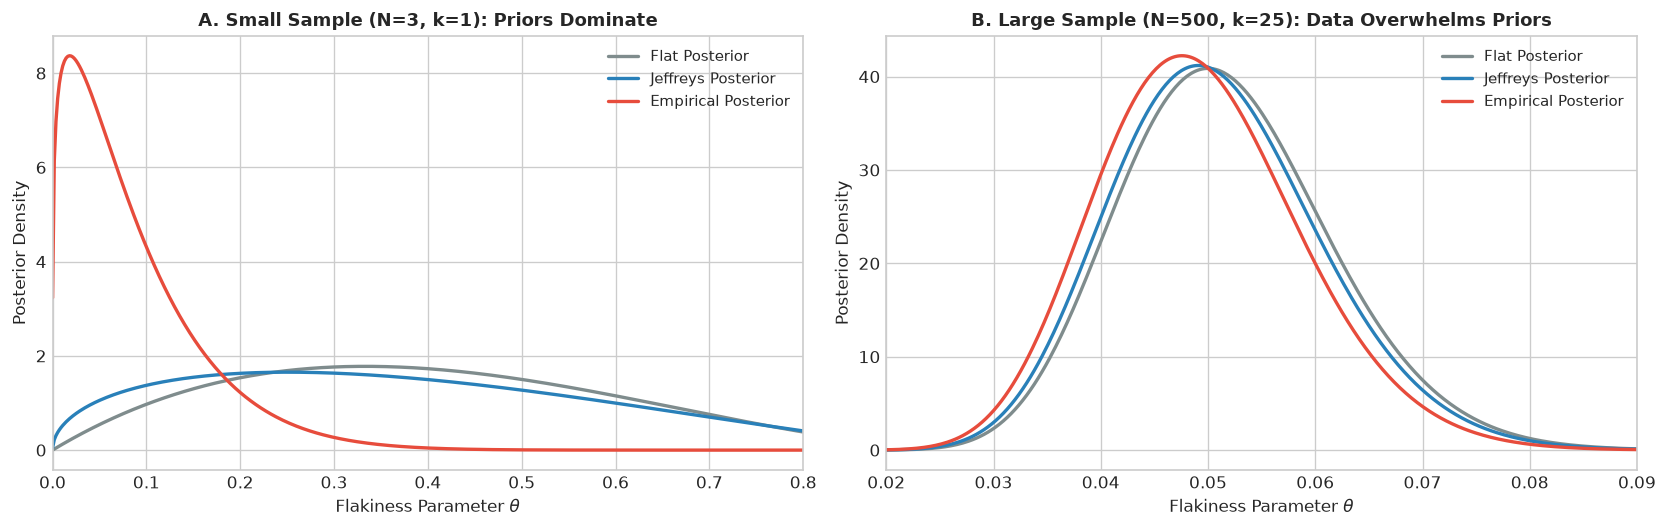

In [6]:
from scipy.stats import beta as beta_dist

def fit_beta_empirical_bayes(mean, std):
    """
    Fits Beta(alpha0, beta0) via method of moments from empirical mean and std.
    """
    var = std ** 2
    if var >= mean * (1.0 - mean):
        raise ValueError("Variance too large for Beta distribution")
    sum_ab = (mean * (1.0 - mean) / var) - 1.0
    alpha = mean * sum_ab
    beta = (1.0 - mean) * sum_ab
    return float(alpha), float(beta)

# Fleet telemetry: mu = 0.02, sigma = 0.04
mu_repo = 0.02
sigma_repo = 0.04
a_fleet, b_fleet = fit_beta_empirical_bayes(mu_repo, sigma_repo)

print("=== Empirical Bayes Fleet Prior Fit ===")
print(f"Monorepo Telemetry: mean = {mu_repo:.2f}, std = {sigma_repo:.2f}")
print(f"Fitted Fleet Prior: Beta({a_fleet:.3f}, {b_fleet:.3f})")
print(f"Effective Prior Sample Size: {a_fleet + b_fleet:.2f} runs\n")

# Prior Sensitivity Comparison
priors = [
    ("Flat Beta(1, 1)", 1.0, 1.0),
    ("Jeffreys Beta(0.5, 0.5)", 0.5, 0.5),
    ("Empirical Fleet Beta(0.225, 11.025)", a_fleet, b_fleet)
]

scenarios = [
    ("Small Sample (N=3, k=1)", 1, 2),
    ("Large Sample (N=500, k=25)", 25, 475)
]

print("=== Prior Sensitivity Analysis ===")
for sc_name, k, passes in scenarios:
    print(f"\n--- {sc_name} ---")
    for name, a0, b0 in priors:
        post_a = a0 + k
        post_b = b0 + passes
        post_mean = post_a / (post_a + post_b)
        # ppf([0.025, 0.975]): 2.5% and 97.5% quantiles for 95% ETI
        low, high = beta_dist.ppf([0.025, 0.975], post_a, post_b)
        print(f"{name:32s} -> Post: Beta({post_a:.3f}, {post_b:.3f}) | Mean: {post_mean:.4f} | 95% ETI: [{low:.4f}, {high:.4f}]")

# Visualization: 2-Panel Diagnostic Figure
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

theta_small = np.linspace(0.0001, 0.9, 500)
colors = ['#7f8c8d', '#2980b9', '#e74c3c']

# Panel 1: Small sample (N=3, k=1)
for (name, a0, b0), c in zip(priors, colors):
    post_a = a0 + 1
    post_b = b0 + 2
    axes[0].plot(theta_small, beta_dist.pdf(theta_small, post_a, post_b),
                 lw=2, color=c, label=f"{name.split()[0]} Posterior")
axes[0].set_title("A. Small Sample (N=3, k=1): Priors Dominate", fontsize=11, fontweight='bold')
axes[0].set_xlabel(r"Flakiness Parameter $\theta$", fontsize=10)
axes[0].set_ylabel("Posterior Density", fontsize=10)
axes[0].set_xlim(0, 0.8)
axes[0].legend(fontsize=9)

# Panel 2: Large sample (N=500, k=25)
theta_large = np.linspace(0.01, 0.10, 500)
for (name, a0, b0), c in zip(priors, colors):
    post_a = a0 + 25
    post_b = b0 + 475
    axes[1].plot(theta_large, beta_dist.pdf(theta_large, post_a, post_b),
                 lw=2, color=c, label=f"{name.split()[0]} Posterior")
axes[1].set_title("B. Large Sample (N=500, k=25): Data Overwhelms Priors", fontsize=11, fontweight='bold')
axes[1].set_xlabel(r"Flakiness Parameter $\theta$", fontsize=10)
axes[1].set_ylabel("Posterior Density", fontsize=10)
axes[1].set_xlim(0.02, 0.09)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


---

## 7. 3-Tier Exercises & Explorations

### Tier 1: Warmup — The Loaded Die
Use `solve_brandeis_dice` to find the MaxEnt probability of rolling a $6$ if the observed average of the die is:
1. $\mathbb{E}[X] = 4.0$
2. $\mathbb{E}[X] = 5.0$
3. $\mathbb{E}[X] = 5.5$

### Tier 2: Intermediate — The Microservice Latency Prior
A backend microservice has an observed average response latency of $\mu = 85\text{ ms}$ and a hard lower bound of $15\text{ ms}$ (network round-trip speed of light).
1. Formulate the MaxEnt distribution on domain $[15, \infty)$.
2. Calculate the probability that a request takes longer than $250\text{ ms}$ under this MaxEnt prior.

### Tier 3: Advanced Research — 2D MaxEnt with Covariance Constraint
Extend the numerical optimizer to find the maximum entropy joint distribution $P(X, Y)$ on a $3 \times 3$ grid given:
1. Marginal means $\mathbb{E}[X] = 0, \mathbb{E}[Y] = 0$.
2. Covariance $\text{Cov}(X, Y) = 0.40$.
Observe how MaxEnt naturally creates the bivariate Gaussian form on discrete lattices!


In [7]:
# Solution verification for Tier 1:
print("Tier 1 Solutions (Probability of rolling a 6):")
for m in [4.0, 5.0, 5.5]:
    p_opt = solve_brandeis_dice(m)
    print(f"Mean = {m:.1f}: P(Face = 6) = {p_opt[5]:.4f} ({p_opt[5]*100:.1f}%)")


Tier 1 Solutions (Probability of rolling a 6):
Mean = 4.0: P(Face = 6) = 0.2468 (24.7%)
Mean = 5.0: P(Face = 6) = 0.4781 (47.8%)
Mean = 5.5: P(Face = 6) = 0.6639 (66.4%)


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/03_maximum_entropy_priors.ipynb) | [Prev: Ch 02: The Price of Optimism (Python)](02_relative_entropy_and_prior_penalties.ipynb) | [Next: Ch 04: Shared Outages & Venn Geometry (Python)](04_mutual_information_and_venn_geometry.ipynb)**
